# EN4554 Assignment 2 - Task 3: Regularization and residual connections

- **(a)** A small CNN with batch norm trained on only **5k** training images: baseline, weight decay, dropout, flip+crop, cutout, mixup and all combined (cutout, mixup and flip+crop are implemented by hand). Train accuracy, validation accuracy and the gap are tabulated and the curves plotted.
- **(b)** CIFAR-style **plain** vs **residual** networks of depth 6n+2 (8, 20, 56). The two families differ *only* in the shortcut; training loss vs epoch is plotted and explained.

Data split, seed and normalisation are identical to Tasks 1 and 2 (45k train / 5k validation, statistics from the training split only). The test set is not used.

In [1]:
import math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
print('Using device:', device)

Using device: cuda


## Data: CIFAR-10 (45k train / 5k val), same split as Tasks 1-2

In [2]:
raw = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X_all = torch.from_numpy(raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()
y_all = torch.tensor(raw.targets, dtype=torch.long)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
del X_all

mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)       # training-split statistics only
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
X_tr, X_va = ((X_tr - mean) / std).to(device), ((X_va - mean) / std).to(device)
y_tr, y_va = y_tr.to(device), y_va.to(device)
print('Train:', tuple(X_tr.shape), '| Val:', tuple(X_va.shape))

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct  += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

100%|██████████| 170M/170M [58:01<00:00, 49.0kB/s]


Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)


## Task 3(a) - Regularisation with only 5k training images


5k subset class counts: [530, 483, 478, 478, 493, 497, 517, 518, 511, 495]


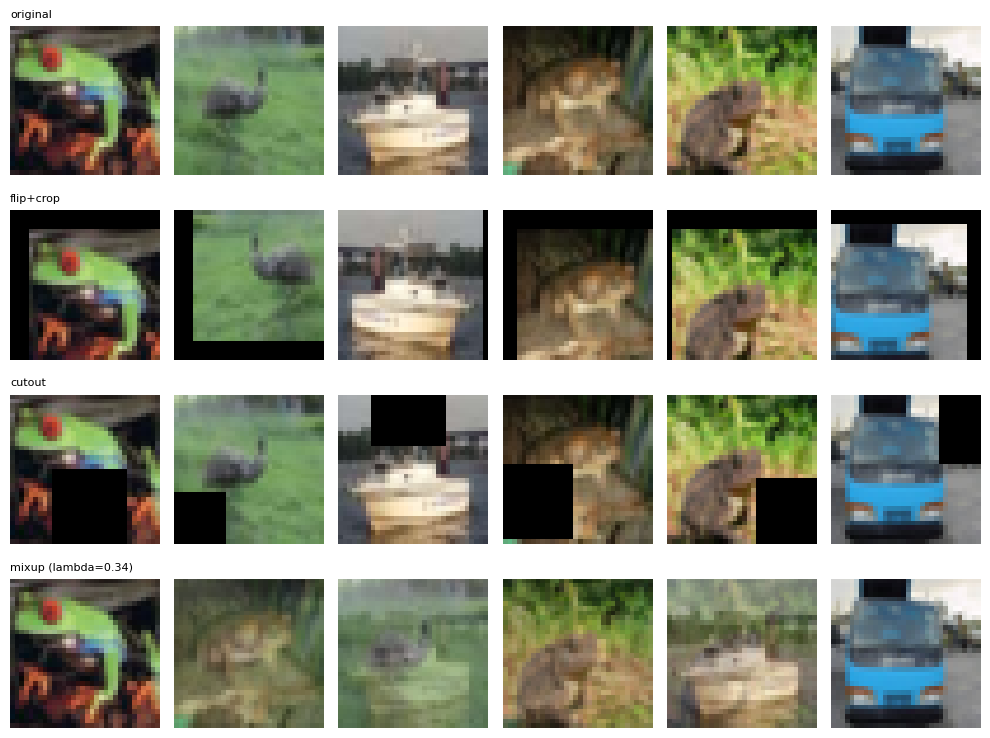

In [3]:
N_SMALL = 5000
X5, y5 = X_tr[:N_SMALL], y_tr[:N_SMALL]
print('5k subset class counts:', torch.bincount(y5.cpu(), minlength=10).tolist())

# ---------- augmentations, implemented by hand (batched, on the device) ----------
def random_flip(x):
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    N, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))                                      # zero padding
    oy = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)[None, :]           # (N,H)
    cols = ox[:, None] + torch.arange(W, device=x.device)[None, :]           # (N,W)
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows[:, None, :, None], cols[:, None, None, :]]

def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device); cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :]; xs = torch.arange(W, device=x.device)[None, :]
    my = (ys >= (cy - size // 2)[:, None]) & (ys < (cy + size // 2)[:, None])   # (N,H)
    mx = (xs >= (cx - size // 2)[:, None]) & (xs < (cx + size // 2)[:, None])   # (N,W)
    mask = (my[:, :, None] & mx[:, None, :])[:, None]                          # (N,1,H,W)
    return x.masked_fill(mask, 0.0)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    j = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[j], y, y[j], lam

# quick visual check of the augmentations on real (un-normalised) images
set_seed(0)
vis = (X5[:6] * std.to(device) + mean.to(device)).clamp(0, 1)
mx_img, _, _, lam_vis = mixup(vis, y5[:6])
rows = {'original': vis, 'flip+crop': random_crop(random_flip(vis)), 'cutout': cutout(vis), f'mixup (lambda={lam_vis:.2f})': mx_img}
fig, ax = plt.subplots(len(rows), 6, figsize=(10, 1.9 * len(rows)))
for r, (name, imgs) in enumerate(rows.items()):
    for c in range(6):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis('off')
    ax[r, 0].set_title(name, fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In [4]:
class SmallBNCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), p_drop=0.0, n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for c in channels:
            layers += [nn.Conv2d(cin, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            cin = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(cin, n_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x): return self.head(self.features(x))

print('SmallBNCNN parameters:', sum(p.numel() for p in SmallBNCNN().parameters()))

EPOCHS_A, SEEDS_A, BS_A, LR_A = 60, (0, 1, 2), 128, 0.05
CONFIGS = {
    'baseline':      dict(),
    'weight decay':  dict(wd=5e-4),
    'dropout':       dict(drop=0.5),
    'flip+crop':     dict(flipcrop=True),
    'cutout':        dict(cutout=True),
    'mixup':         dict(mixup=True),
    'all combined':  dict(wd=5e-4, drop=0.5, flipcrop=True, cutout=True, mixup=True),
}

def train_small(cfg, seed, epochs=EPOCHS_A, bs=BS_A, lr=LR_A):
    set_seed(seed)
    model = SmallBNCNN(p_drop=cfg.get('drop', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    N = len(X5); hist = dict(tr_acc=[], va_acc=[], tr_loss=[], va_loss=[])
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device)
        for i in range(0, N - bs + 1, bs):                           # drop the incomplete last batch (BN)
            idx = order[i:i + bs]; x, y = X5[idx], y5[idx]
            if cfg.get('flipcrop'): x = random_crop(random_flip(x))
            if cfg.get('cutout'):   x = cutout(x)
            opt.zero_grad(set_to_none=True)
            if cfg.get('mixup'):
                x, ya, yb, lam = mixup(x, y)
                out = model(x); loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb)
            else:
                loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
        sched.step()
        tl, ta = evaluate(model, X5, y5)                             # CLEAN train metrics, eval mode
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tl); hist['tr_acc'].append(ta); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

SmallBNCNN parameters: 288746


In [5]:
results_a = {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    for seed in SEEDS_A:
        results_a[(name, seed)] = h = train_small(cfg, seed)
        print(f"{name:<13} seed={seed}  train acc {h['tr_acc'][-1]:6.2f}%  val acc {h['va_acc'][-1]:6.2f}%  "
              f"gap {h['tr_acc'][-1] - h['va_acc'][-1]:6.2f}  [{time.time() - t0:.0f}s]")

baseline      seed=0  train acc 100.00%  val acc  68.36%  gap  31.64  [74s]
baseline      seed=1  train acc 100.00%  val acc  68.34%  gap  31.66  [159s]
baseline      seed=2  train acc 100.00%  val acc  68.06%  gap  31.94  [255s]
weight decay  seed=0  train acc 100.00%  val acc  68.92%  gap  31.08  [350s]
weight decay  seed=1  train acc 100.00%  val acc  67.82%  gap  32.18  [446s]
weight decay  seed=2  train acc 100.00%  val acc  68.88%  gap  31.12  [541s]
dropout       seed=0  train acc 100.00%  val acc  67.34%  gap  32.66  [636s]
dropout       seed=1  train acc 100.00%  val acc  67.04%  gap  32.96  [732s]
dropout       seed=2  train acc 100.00%  val acc  65.96%  gap  34.04  [827s]
flip+crop     seed=0  train acc  97.42%  val acc  74.84%  gap  22.58  [922s]
flip+crop     seed=1  train acc  97.84%  val acc  74.64%  gap  23.20  [1019s]
flip+crop     seed=2  train acc  97.34%  val acc  75.42%  gap  21.92  [1114s]
cutout        seed=0  train acc 100.00%  val acc  71.30%  gap  28.70  [1208

configuration      train acc (%)       val acc (%)   gap (train - val)   best-epoch val acc  final val loss
baseline           100.00 ± 0.00      68.25 ± 0.14        31.75 ± 0.14                68.71           1.332
weight decay       100.00 ± 0.00      68.54 ± 0.51        31.46 ± 0.51                68.86           1.174
dropout            100.00 ± 0.00      66.78 ± 0.59        33.22 ± 0.59                67.21           1.455
flip+crop           97.53 ± 0.22      74.97 ± 0.33        22.57 ± 0.52                75.21           0.868
cutout             100.00 ± 0.00      71.19 ± 0.09        28.81 ± 0.09                71.40           1.138
mixup              100.00 ± 0.00      68.25 ± 0.21        31.75 ± 0.21                68.65           0.975
all combined        77.13 ± 0.37      68.65 ± 0.37         8.47 ± 0.01                69.22           0.877


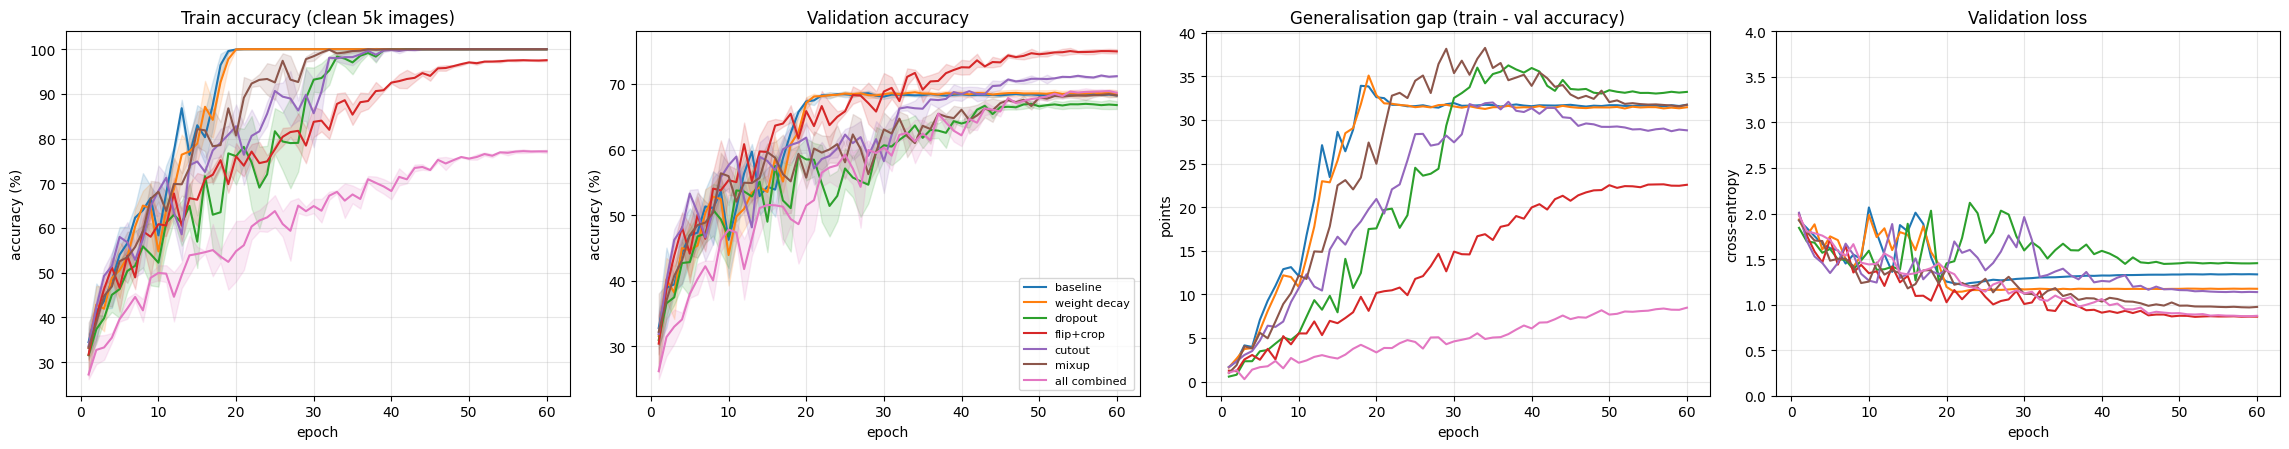

In [6]:
def stack(name, key): return np.array([results_a[(name, s)][key] for s in SEEDS_A])     # (seeds, epochs)

print(f"{'configuration':<14}{'train acc (%)':>18}{'val acc (%)':>18}{'gap (train - val)':>20}{'best-epoch val acc':>21}{'final val loss':>16}")
for name in CONFIGS:
    tr, va = stack(name, 'tr_acc')[:, -1], stack(name, 'va_acc')[:, -1]
    best = stack(name, 'va_acc').max(1); vl = stack(name, 'va_loss')[:, -1]
    print(f'{name:<14}{tr.mean():>11.2f} ± {tr.std():<4.2f}{va.mean():>11.2f} ± {va.std():<4.2f}{(tr - va).mean():>13.2f} ± {(tr - va).std():<4.2f}{best.mean():>21.2f}{vl.mean():>16.3f}')

ep = np.arange(1, EPOCHS_A + 1)
cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(1, 4, figsize=(23, 4.6))
for k, name in enumerate(CONFIGS):
    for a, key in zip(ax[:2], ('tr_acc', 'va_acc')):
        m, s = stack(name, key).mean(0), stack(name, key).std(0)
        a.plot(ep, m, color=cmap(k), label=name); a.fill_between(ep, m - s, m + s, color=cmap(k), alpha=.15)
    ax[2].plot(ep, (stack(name, 'tr_acc') - stack(name, 'va_acc')).mean(0), color=cmap(k), label=name)
    ax[3].plot(ep, stack(name, 'va_loss').mean(0), color=cmap(k), label=name)
ax[0].set(title='Train accuracy (clean 5k images)', xlabel='epoch', ylabel='accuracy (%)')
ax[1].set(title='Validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
ax[2].set(title='Generalisation gap (train - val accuracy)', xlabel='epoch', ylabel='points')
ax[3].set(title='Validation loss', xlabel='epoch', ylabel='cross-entropy', ylim=(0, 4))
for a in ax: a.grid(alpha=.3)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Task 3(b) - Plain vs residual networks of depth 6n+2 (8, 20, 56)


In [7]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin
    def shortcut(self, x):
        if self.stride == 1 and self.extra == 0: return x                         # identity
        return F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))   # option A
    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual: out = out + self.shortcut(x)                             # the ONLY difference
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        blocks, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for b in range(n):
                blocks.append(Block(cin, cout, stride if b == 0 else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

def make(n, residual):
    set_seed(0); return CifarNet(n, residual).to(device)         # same seed -> identical initial weights for both families

# sanity checks: depth = number of weight layers, equal parameter counts, identical initial weights
for n in (1, 3, 9):
    mp, mr = make(n, False), make(n, True)
    depth = 1 + sum(isinstance(m, nn.Conv2d) for m in mp.blocks.modules()) + 1
    same_init = all(torch.equal(a, b) for a, b in zip(mp.parameters(), mr.parameters()))
    print(f'n={n}: depth {depth} (6n+2 = {6 * n + 2}) | params plain {sum(p.numel() for p in mp.parameters()):,} '
          f'= residual {sum(p.numel() for p in mr.parameters()):,} | identical initial weights: {same_init}')

n=1: depth 8 (6n+2 = 8) | params plain 75,290 = residual 75,290 | identical initial weights: True
n=3: depth 20 (6n+2 = 20) | params plain 269,722 = residual 269,722 | identical initial weights: True
n=9: depth 56 (6n+2 = 56) | params plain 853,018 = residual 853,018 | identical initial weights: True


In [8]:
# Diagnostic at initialisation: gradient norm of the stem conv vs the last block's second conv, one minibatch
set_seed(1); xb, yb = X_tr[:256], y_tr[:256]
print(f"{'depth':>6}{'family':>10}{'|grad stem conv|':>20}{'|grad last conv|':>20}{'ratio first/last':>20}")
for n in (1, 3, 9):
    for residual in (False, True):
        m = make(n, residual); m.train(); m.zero_grad()
        F.cross_entropy(m(xb), yb).backward()
        g_first = m.stem[0].weight.grad.norm().item(); g_last = m.blocks[-1].conv2.weight.grad.norm().item()
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{g_first:>20.4f}{g_last:>20.4f}{g_first / g_last:>20.3f}")

 depth    family    |grad stem conv|    |grad last conv|    ratio first/last
     8     plain              0.2276              0.4061               0.560
     8  residual              0.2795              0.5443               0.513
    20     plain              0.7464              0.3175               2.351
    20  residual              0.8209              1.2047               0.681
    56     plain            377.3403              0.7394             510.301
    56  residual              1.5321              0.7539               2.032


In [9]:
EPOCHS_B, BS_B, LR_B, WD_B, DEPTHS = 20, 128, 0.1, 1e-4, (1, 3, 9)       # n = 1, 3, 9  ->  depth 8, 20, 56

def train_cifarnet(n, residual, epochs=EPOCHS_B, bs=BS_B):
    model = make(n, residual)
    opt = torch.optim.SGD(model.parameters(), lr=LR_B, momentum=0.9, weight_decay=WD_B)
    N = len(X_tr); steps_per_ep = N // bs; total = epochs * steps_per_ep; warm = steps_per_ep
    lr_at = lambda t: LR_B * (t + 1) / warm if t < warm else 0.5 * LR_B * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
    hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False); step = 0
    set_seed(0)                                                      # identical minibatch order for plain and residual
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, steps_per_ep * bs, bs):
            for g in opt.param_groups: g['lr'] = lr_at(step)
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx]); loss.backward(); opt.step()
            run += loss.detach() * bs; step += 1
        tr = run.item() / (steps_per_ep * bs)
        if not math.isfinite(tr):
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

results_b = {}
t0 = time.time()
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)] = train_cifarnet(n, residual)
        print(f"depth {6 * n + 2:>2} {'residual' if residual else 'plain   '}  final train loss {h['tr_loss'][-1]:.4f}  "
              f"final val acc {h['va_acc'][-1]:.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time() - t0:.0f}s]")

depth  8 plain     final train loss 0.1903  final val acc 79.88%   [91s]
depth  8 residual  final train loss 0.1926  final val acc 79.46%   [186s]
depth 20 plain     final train loss 0.0279  final val acc 83.96%   [445s]
depth 20 residual  final train loss 0.0045  final val acc 83.76%   [713s]
depth 56 plain     final train loss 0.3337  final val acc 67.08%   [1477s]
depth 56 residual  final train loss 0.0014  final val acc 84.42%   [2271s]


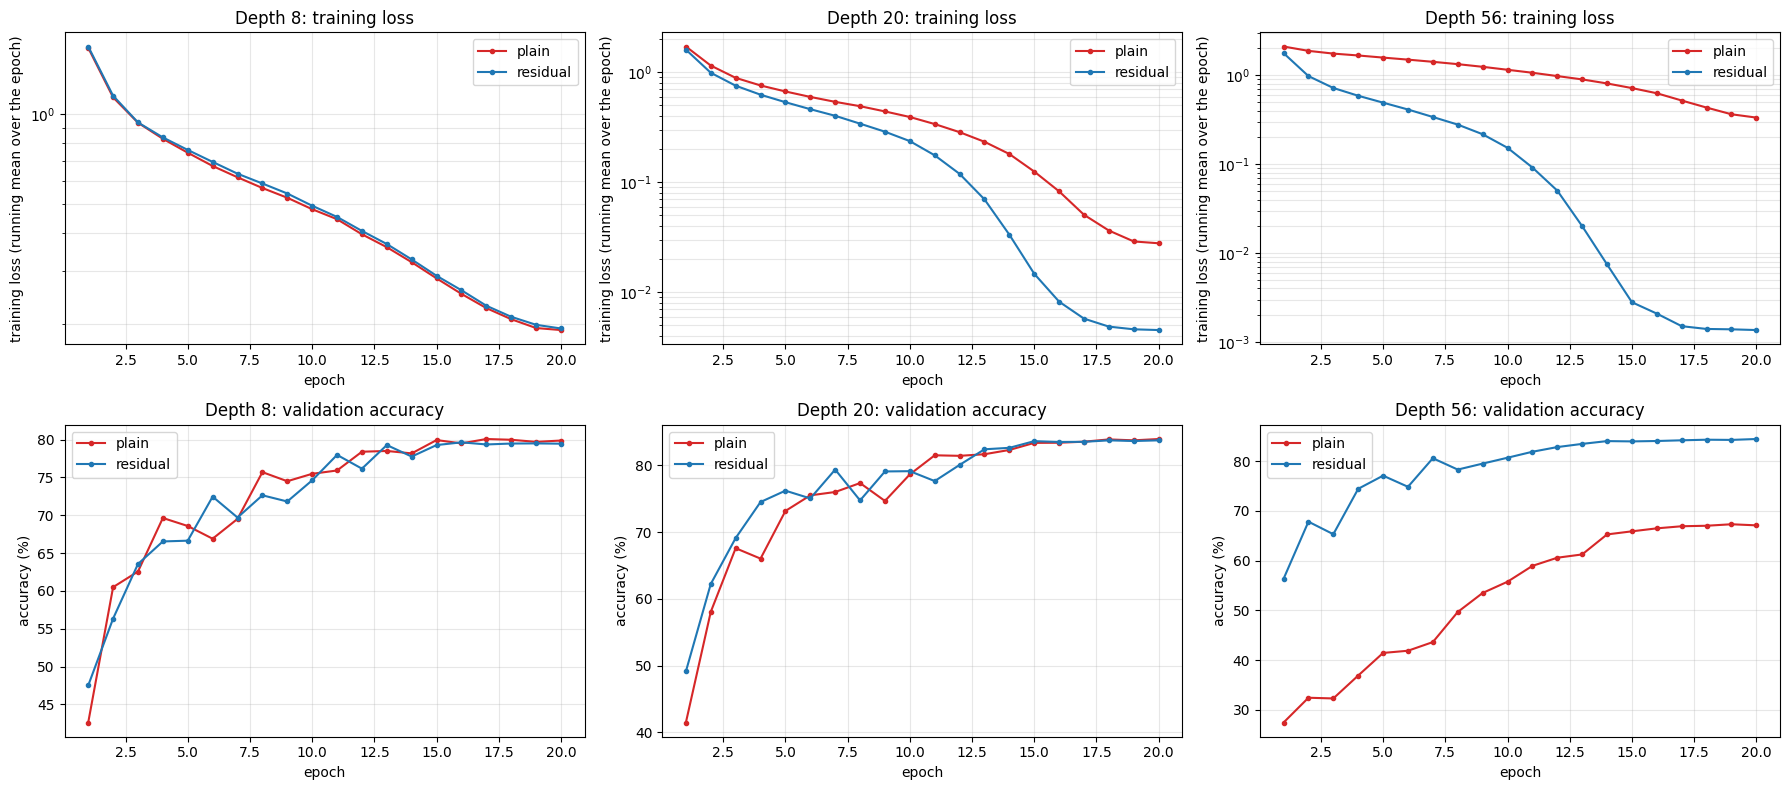

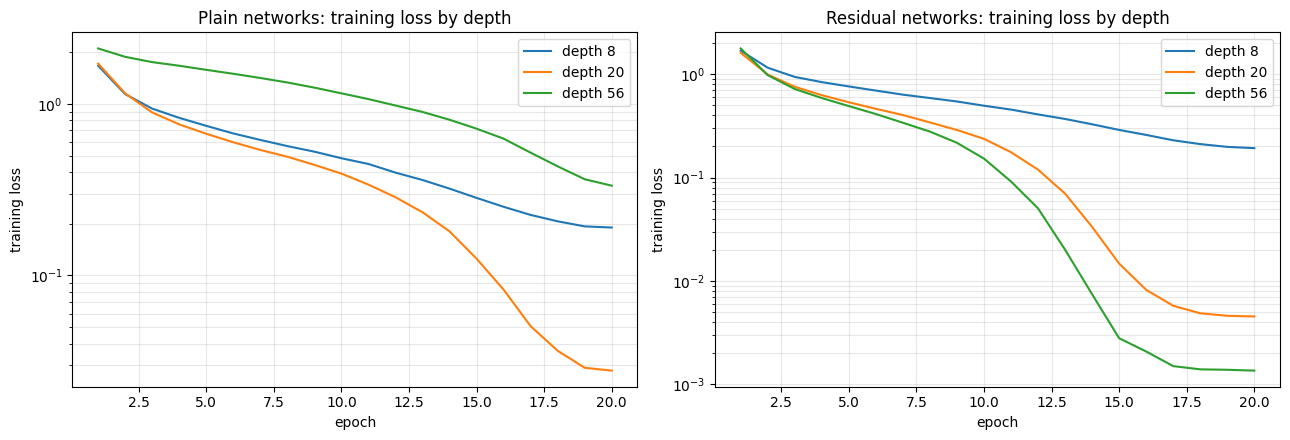

 depth    family    params  train loss @ep1  train loss @ep5  final train loss  final val acc (%)
     8     plain    75,290           1.6684           0.7445            0.1903              79.88
     8  residual    75,290           1.6853           0.7605            0.1926              79.46
    20     plain   269,722           1.7160           0.6696            0.0279              83.96
    20  residual   269,722           1.6078           0.5349            0.0045              83.76
    56     plain   853,018           2.1028           1.5782            0.3337              67.08
    56  residual   853,018           1.7719           0.4912            0.0014              84.42


In [10]:
ep = np.arange(1, EPOCHS_B + 1)
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for c, n in enumerate(DEPTHS):
    for residual, col in ((False, 'tab:red'), (True, 'tab:blue')):
        h = results_b[(n, residual)]; lab = 'residual' if residual else 'plain'
        ax[0, c].plot(ep, h['tr_loss'], 'o-', ms=3, color=col, label=lab)
        ax[1, c].plot(ep, h['va_acc'], 'o-', ms=3, color=col, label=lab)
    ax[0, c].set(title=f'Depth {6 * n + 2}: training loss', xlabel='epoch', ylabel='training loss (running mean over the epoch)', yscale='log')
    ax[1, c].set(title=f'Depth {6 * n + 2}: validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
    for r in (0, 1): ax[r, c].grid(alpha=.3, which='both'); ax[r, c].legend()
plt.tight_layout(); plt.show()

# all depths together per family: the degradation problem shows as plain-56 above plain-20
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, residual in zip(ax, (False, True)):
    for n in DEPTHS: a.plot(ep, results_b[(n, residual)]['tr_loss'], label=f'depth {6 * n + 2}')
    a.set(title=f"{'Residual' if residual else 'Plain'} networks: training loss by depth", xlabel='epoch', ylabel='training loss', yscale='log')
    a.grid(alpha=.3, which='both'); a.legend()
plt.tight_layout(); plt.show()

print(f"{'depth':>6}{'family':>10}{'params':>10}{'train loss @ep1':>17}{'train loss @ep5':>17}{'final train loss':>18}{'final val acc (%)':>19}")
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)]; P = sum(p.numel() for p in make(n, residual).parameters())
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{P:>10,}{h['tr_loss'][0]:>17.4f}{h['tr_loss'][4]:>17.4f}{h['tr_loss'][-1]:>18.4f}{h['va_acc'][-1]:>19.2f}")